# 01 · Earned Autonomy for LLM Agents in a Real Multi-Business Operation

**Author:** Juan Antonio Sainz Gálvez · Applied AI & ML, Conestoga College · [GitHub](https://github.com/antoniosg2025-stack)

<a href="https://colab.research.google.com/github/antoniosg2025-stack/applied-ai-research-portfolio/blob/main/notebooks/01_human_agent_coordination.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

## Abstract

I run several small businesses in Canada and Mexico (vending machines, a phone self-checkout retail system, a portfolio-analysis connector and content channels) that are operated day to day by a team of LLM agents and a few human specifiers. Every agent follows one rule: **nothing reaches production without the owner's explicit approval**. This works, but it does not scale: the owner becomes the bottleneck, and approving everything invites rubber-stamping.

This notebook (1) reviews current research on LLM multi-agent systems, human-agent collaboration and graduated autonomy; (2) documents the coordination methodology I built and maps it to that literature; and (3) runs a reproducible simulation comparing three oversight policies — *approve everything*, *risk-tiered approval* and *earned autonomy* (autonomy granted per agent and per action type from its measured outcome record). The goal is to frame a thesis question: **can an agent earn autonomy from measured outcomes, safely, inside a real operation?**


## 1. Context: the operation behind this notebook

| Element | What it is in practice |
|---|---|
| Project agents | One LLM agent per product (retail self-checkout, investment connector, content channels, SEO). Each writes code and content only in its own repositories |
| Specifiers | Humans (store operators) who propose features as written specs and test them in a sandbox |
| Coordinator agent | Reviews finished specs across projects and prepares one daily approval summary |
| Owner | The only person who can approve a production release (a Cloud Build trigger with *Require approval*) |
| Sandbox | A full copy of each system with its own database and payments in test mode |

The methodology is **spec-driven**: the written spec is the source of truth; the cycle is *Draft → Building → Testing → Done → Approved → Live*. Rule 1 is enforced by three locks: the rule written at the top of every agent's instructions, agents that hold no production key, and an approval button only the owner can press.


## 2. Literature review

### 2.1 LLM multi-agent systems and why they fail
Surveys organize LLM multi-agent collaboration by type, strategy, structure and coordination/orchestration [3], and frameworks such as AutoGen [11] and MetaGPT [12] made role-based agent teams practical. A hierarchical taxonomy of design patterns and industrial applications is given in [13].

Reliability, however, is the open problem. Cemri et al. [1] annotated 1,642 execution traces from seven multi-agent frameworks and built **MAST**, a taxonomy of 14 failure modes in three groups: specification and system design, inter-agent misalignment, and task verification. Their key finding is that failures come mostly from *system design and inter-agent misalignment*, not only from the underlying model. One mode, *failing to ask for clarification*, maps directly to the question of when an agent should stop and involve a human. Automated failure attribution — finding *which* agent caused a failure and *when* — is studied in [10].

### 2.2 Humans in the loop
A survey of LLM-based human-agent systems [2] defines autonomy levels from full automation to human-driven work and treats humans as active participants who supervise, intervene and give feedback. Magentic-UI [4] is a concrete human-in-the-loop agentic system, and HAS-Bench [9] evaluates agents under configurable levels of human participation. A position paper [8] argues that human-agent systems should precede full AI autonomy.

A 2026 review of agent harness engineering [5] describes three oversight patterns used in production: **pre-execution approval**, **post-execution review** and **escalation triggers**, and concludes that the level of autonomy is not a property of the model but a configurable parameter of the harness, adjustable per task and per tool.

### 2.3 Graduated, earned autonomy
The 2026 Singapore Consensus on AI safety research priorities [6] proposes *graduated autonomy*: as agents demonstrate reliability, approval requirements can be relaxed, so autonomy is **earned rather than granted by default**, using demonstrated performance data instead of static levels. Kasirzadeh and Gabriel's autonomy framework, applied in a user study [7], includes a *risk-contingent* level where the agent acts alone except for critical determinations. In industry, OWASP lists *excessive agency* (excessive functionality, permissions and autonomy) among the top risks of LLM applications.

### 2.4 Closest work at the University of Calgary
- **B. Far** studies agent-oriented software engineering with LLMs (LLM-based MaSE, 2025) and multi-agent RAG frameworks for industrial prediction (2025).
- **S. Drew** studies trust in AI agents based on measured outcomes (LEGIT, 2026) and LLM agents that run a verification step before acting (FL-MAESTRO, GLOBECOM 2026).

**Gap.** Most evaluations use benchmarks or simulated tasks. There is little evidence from *real, multi-business operations* where agents touch money, customers and production systems, and where autonomy must be granted per agent and per action type over time.


## 3. Mapping the methodology to the literature

| Practice in my operation | Concept in the literature |
|---|---|
| Rule 1: nothing reaches production without owner approval | Pre-execution approval gate [5] |
| Agents have no production key; owner-only approval button | Least privilege against excessive agency (OWASP) |
| Sandbox with test payments; specifiers test before *Done* | Post-execution review in a safe environment [5]; humans as active participants [2] |
| One agent per project, one chat per purpose, written roles | Mitigates specification and inter-agent misalignment failures [1] |
| Coordinator sends one daily summary | Batching reviews to reduce approval fatigue |
| Decisions logged newest-first; spec is the source of truth | Shared, persistent context across agents |

**What is missing** is the last idea of [6]: approvals are static. Every action type needs approval forever, regardless of how reliable an agent has proven to be. The simulation below quantifies what that costs and what earned autonomy could change.


## 4. Experiment: three oversight policies

**Setup (all parameters are stated assumptions, not measurements; they are calibrated to the scale of my operation and can be changed below).**

- 4 agents with different true reliability.
- 7 action types in 3 risk tiers. *Money* and *production deploy* are never autonomous (Rule 1 stays).
- Each day every agent proposes actions; each action fails with the agent's true error rate for that type.
- A human reviewer catches a failure with probability 0.95, which **decays as the daily review load grows** (rubber-stamp effect).

**Policies**
1. **Approve all** — every action is reviewed.
2. **Risk-tiered** — only high-risk actions are reviewed.
3. **Earned autonomy** — each (agent, action) pair keeps a Beta posterior of its success rate from reviewed outcomes; the pair becomes autonomous when the 5th percentile of the posterior exceeds 0.97. High-risk actions are always reviewed. Failures of autonomous actions are discovered later half of the time and count against the pair.
4. **Earned autonomy + priority queue** — same as 3, but high-risk items (money, production) go to a separate, short review queue so they are reviewed with full attention.

**Metrics** over 120 days: reviews per day, failures that escaped review, and high-risk failures that escaped.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta

SEED = 7
DAYS = 120

# Action types: (name, risk tier, actions per agent per day)
ACTIONS = pd.DataFrame([
    ("read_data",         "low",    6),
    ("draft_content",     "low",    4),
    ("sandbox_deploy",    "medium", 2),
    ("publish_social",    "medium", 2),
    ("message_client",    "medium", 2),
    ("spend_money",       "high",   0.3),
    ("production_deploy", "high",   0.3),
], columns=["action", "tier", "per_day"])

# True error rate per agent (multiplier over a base rate per tier)
AGENTS = {"retail_agent": 0.6, "investing_agent": 1.0, "content_agent": 1.4, "seo_agent": 0.8}
BASE_ERROR = {"low": 0.01, "medium": 0.03, "high": 0.05}

def reviewer_catch_prob(load):
    """Review accuracy decays once the daily load passes 20 items."""
    return 0.95 * np.exp(-max(0, load - 20) / 40)

ACTIONS

,action,tier,per_day
0,read_data,low,6.0
1,draft_content,low,4.0
2,sandbox_deploy,medium,2.0
3,publish_social,medium,2.0
4,message_client,medium,2.0
5,spend_money,high,0.3
6,production_deploy,high,0.3


In [2]:
POLICIES = ["approve_all", "risk_tiered", "earned_autonomy", "earned_priority"]

def simulate(policy, seed=SEED, days=DAYS, threshold=0.97):
    rng = np.random.default_rng(seed)
    post = {(a, act): [1.0, 1.0] for a in AGENTS for act in ACTIONS.action}  # Beta(1,1)
    rows = []
    for day in range(days):
        proposed = []
        for agent, mult in AGENTS.items():
            for _, r in ACTIONS.iterrows():
                n = rng.poisson(r.per_day)
                err = BASE_ERROR[r.tier] * mult
                for _ in range(n):
                    proposed.append((agent, r.action, r.tier, rng.random() < err))
        def needs_review(agent, action, tier):
            if policy == "approve_all":
                return True
            if tier == "high":
                return True
            if policy == "risk_tiered":
                return False
            a, b = post[(agent, action)]
            return beta.ppf(0.05, a, b) < threshold   # earned autonomy
        flags = [needs_review(*p[:3]) for p in proposed]
        n_review = sum(flags)
        n_high = sum(1 for p, f in zip(proposed, flags) if f and p[2] == "high")
        catch = reviewer_catch_prob(n_review)
        # earned_priority: high-risk items get their own short, fresh review queue
        catch_high = reviewer_catch_prob(n_high) if policy == "earned_priority" else catch
        escaped = escaped_high = 0
        for (agent, action, tier, failed), reviewed in zip(proposed, flags):
            if reviewed:
                c = catch_high if tier == "high" else catch
                caught = failed and rng.random() < c
                if policy in ("earned_autonomy", "earned_priority"):
                    post[(agent, action)][1 if caught else 0] += 1
                if failed and not caught:
                    escaped += 1; escaped_high += tier == "high"
            elif failed:
                escaped += 1; escaped_high += tier == "high"
                # an autonomous failure is discovered later half of the time
                # and counts against that agent's record
                if policy in ("earned_autonomy", "earned_priority") and rng.random() < 0.5:
                    post[(agent, action)][1] += 3
        review = flags
        rows.append(dict(day=day, policy=policy, reviews=n_review,
                         escaped=escaped, escaped_high=escaped_high))
    return pd.DataFrame(rows)

results = pd.concat([simulate(p) for p in POLICIES])
summary = results.groupby("policy").agg(reviews_per_day=("reviews", "mean"),
                                        escaped_total=("escaped", "sum"),
                                        escaped_high_risk=("escaped_high", "sum")).round(1)
summary

,reviews_per_day,escaped_total,escaped_high_risk
policy,,,
approve_all,66.6,95,9
earned_autonomy,40.2,75,6
earned_priority,40.2,69,0
risk_tiered,2.5,128,0


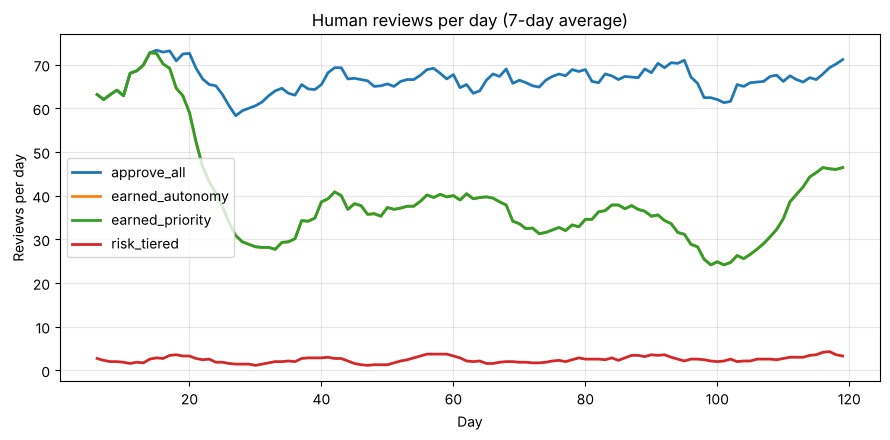

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for p, g in results.groupby("policy"):
    ax.plot(g.day, g.reviews.rolling(7).mean(), label=p, linewidth=2)
ax.set_title("Human reviews per day (7-day average)")
ax.set_xlabel("Day"); ax.set_ylabel("Reviews per day"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

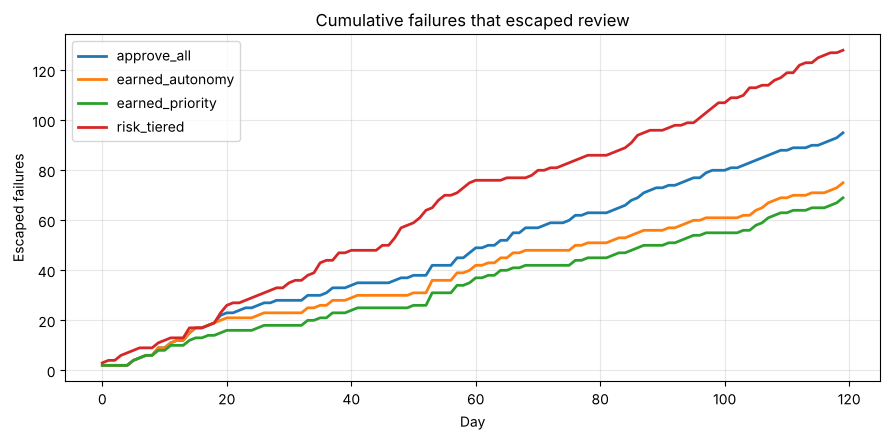

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for p, g in results.groupby("policy"):
    ax.plot(g.day, g.escaped.cumsum(), label=p, linewidth=2)
ax.set_title("Cumulative failures that escaped review")
ax.set_xlabel("Day"); ax.set_ylabel("Escaped failures"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [5]:
# Robustness: repeat with 20 seeds
runs = []
for s in range(20):
    for p in POLICIES:
        d = simulate(p, seed=s)
        runs.append(dict(seed=s, policy=p, reviews_per_day=d.reviews.mean(),
                         escaped=d.escaped.sum(), escaped_high=d.escaped_high.sum()))
robust = pd.DataFrame(runs).groupby("policy").agg(["mean", "std"]).drop(columns="seed").round(1)
robust

reviews_per_day      escaped      escaped_high     
                           mean  std    mean  std         mean  std
policy                                                             
approve_all                66.3  0.8   101.0  8.1         10.0  4.0
earned_autonomy            44.8  2.7    85.7  9.6          6.6  3.6
earned_priority            44.8  2.7    79.6  8.6          0.5  0.7
risk_tiered                 2.4  0.2   129.1  8.3          0.8  0.8

## 5. Discussion

Results (20 seeds, 120 days each; exact numbers are in the robustness table above):

- **Approve all** produces the highest review load (about 66 reviews per day). At that load the reviewer's accuracy decays, so failures still escape — including high-risk ones. Blanket approval turns oversight into a reflex, the concern raised in [5] and [6].
- **Risk-tiered** reduces the load to a few reviews per day and catches almost every high-risk failure, because the reviewer is fresh — but it lets every low- and medium-risk failure through, so it has the most escaped failures overall.
- **Earned autonomy** cuts the load by about a third and reduces escaped failures compared with *approve all*, because reliable (agent, action) pairs graduate while weak ones stay under review.
- **Earned autonomy + priority queue** keeps those gains and protects the high-risk actions by reviewing them separately.

The key insight is that **the number of approvals matters as much as which actions are approved**: oversight quality is a limited resource, and autonomy should be earned where it frees the most attention for the decisions that cannot be undone.

**Limitations.** Error rates, volumes and the reviewer-fatigue curve are assumptions. Real agents drift (a model update can change reliability overnight), errors are not independent, and some failures are only visible days later. These are exactly the questions a thesis would answer with real logs.

## 6. Thesis questions

1. **Measured trust.** How should an agent's outcome record (sandbox tests, specifier feedback, production incidents) be turned into a trust score per action type, and how fast should trust decay after a model change? (Connects to Drew's outcome-based trust.)
2. **Failure attribution in real operations.** Can MAST-style failure modes [1] be annotated automatically from real agent logs to decide *which* agent loses autonomy? (Connects to Far's agent-oriented software engineering.)
3. **Verification before action.** Which actions benefit most from an automatic verification agent before the human gate, and how much human load does it remove without increasing escaped failures?

## References

1. Cemri, M., Pan, M. Z., et al. (2025). *Why Do Multi-Agent LLM Systems Fail?* arXiv:2503.13657.
2. *LLM-Based Human-Agent Collaboration and Interaction Systems: A Survey* (2025). arXiv:2505.00753.
3. *Multi-Agent Collaboration Mechanisms: A Survey of LLMs* (2025). arXiv:2501.06322.
4. Mozannar, H., et al. (2025). *Magentic-UI: Towards Human-in-the-loop Agentic Systems.* arXiv:2507.22358.
5. *Externalization in LLM Agents: A Unified Review of Memory, Skills, Protocols and Harness Engineering* (2026). arXiv:2604.08224.
6. *The 2026 Singapore Consensus on Global AI Safety Research Priorities* (2026). arXiv:2608.14611.
7. *Autonomy Reshapes How Personalization Affects Privacy Concerns and Trust in LLM Agents* (2025). arXiv:2510.04465 (applies Kasirzadeh & Gabriel's autonomy framework).
8. *A Call for Collaborative Intelligence: Why Human-Agent Systems Should Precede AI Autonomy* (2025). arXiv:2506.09420.
9. *HAS-Bench: Evaluating LLM-Based Human-Agent Systems under Configurable Human Participation* (2026). arXiv:2607.04329.
10. *Which Agent Causes Task Failures and When? On Automated Failure Attribution of LLM Multi-Agent Systems* (2025).
11. Wu, Q., et al. (2024). *AutoGen: Enabling Next-Gen LLM Applications via Multi-Agent Conversation.* COLM 2024.
12. Hong, S., et al. (2024). *MetaGPT: Meta Programming for a Multi-Agent Collaborative Framework.* ICLR 2024.
13. *A Taxonomy of Hierarchical Multi-Agent Systems: Design Patterns, Coordination Mechanisms, and Industrial Applications* (2025). arXiv:2508.12683.
14. OWASP (2025). *Top 10 for LLM Applications: LLM06 Excessive Agency.*
